In [1]:
pacman::p_load(ggplot2,tidyverse,patchwork,ggrepel)

In [2]:
scaling_relationships=read.csv("../data/merged_results_bounds_2.csv") %>%
    dplyr::filter(!(is.na(metaT_p_half_sat)&is.na(metaT_n_half_sat)))

In [12]:
scaling_relationships %>% dplyr::filter(taxon=="Hemiaulales")

X,Unnamed..0,taxon,diameter,min_diameter,max_diameter,pft,parameter_a_gr,parameter_a_gr_denom,parameter_b_gr,⋯,half_sat_n_max,half_sat_p_max,Taxon_x,metaT_p_half_sat,conf_interval_intercept_low,conf_interval_intercept_high,Taxon_y,metaT_n_half_sat,n_low,n_high
<int>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
5,6,Hemiaulales,50,10,150,Diatom,2.889699e-05,86400,-0.1,⋯,20.66105,1.26397,Hemiaulales,0.02780457,-0.0961801,0.08316536,,NA,NA,NA


In [5]:
all_scalings= read.csv("../data/scaling_relationships_calc.csv")

In [8]:
all_scalings %>% dplyr::select(taxon,half_sat_n,half_sat_p) %>%
    dplyr::arrange(half_sat_n)

taxon,half_sat_n,half_sat_p
<chr>,<dbl>,<dbl>
Mamiellales,0.4956242,0.03032054
Parmales,0.8689340,0.05315831
Prymnesiales,1.3142690,0.08040234
Phaeocystales,1.3142690,0.08040234
Isochrysidales,1.5234250,0.09319776
Suessiales,2.3041914,0.14096230
Gymnodiniales,2.3041914,0.14096230
Leptocylindrales,3.2000184,0.19576583
Cryptomonadales,3.2000184,0.19576583


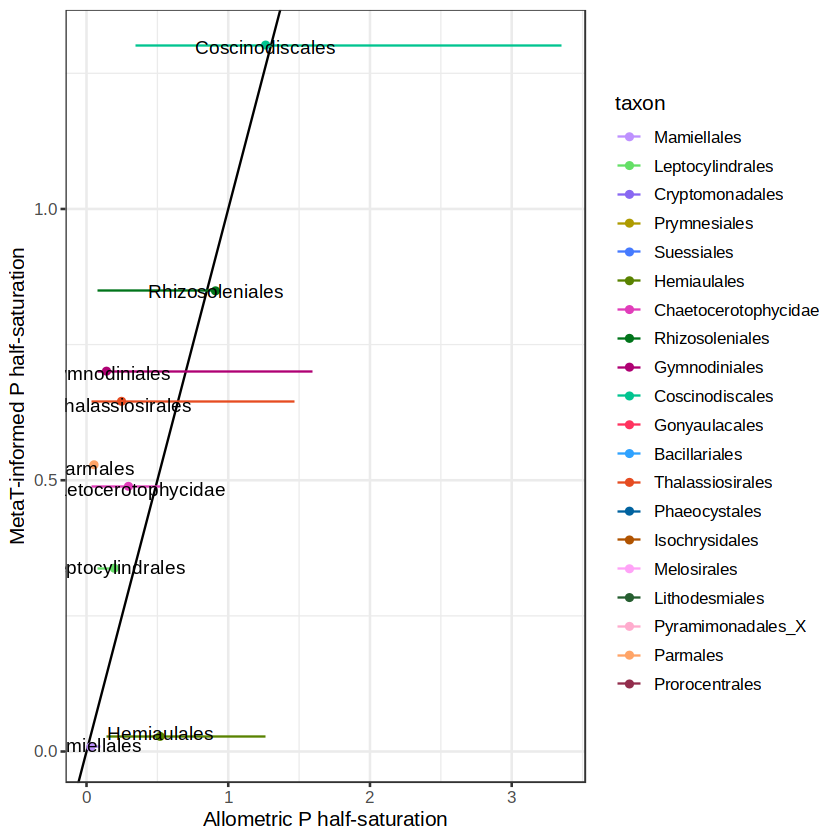

In [5]:
p_half_sat = ggplot(scaling_relationships %>%
                   dplyr::mutate(taxon=factor(taxon))%>%
                   dplyr::filter(metaT_p_half_sat>0))+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_p,
                    y=metaT_p_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_segment(aes(x=half_sat_p_min,xend=half_sat_p_max,
                    y=metaT_p_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_text(aes(x=half_sat_p,
                   y=metaT_p_half_sat,
                   label=taxon),
               position="jitter",size=4) + 
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE)+ 
    xlab("Allometric P half-saturation")+
    ylab("MetaT-informed P half-saturation")
p_half_sat
ggsave("../figures/half_sats_p_range.png",width=10,height=10,units="in")

Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”


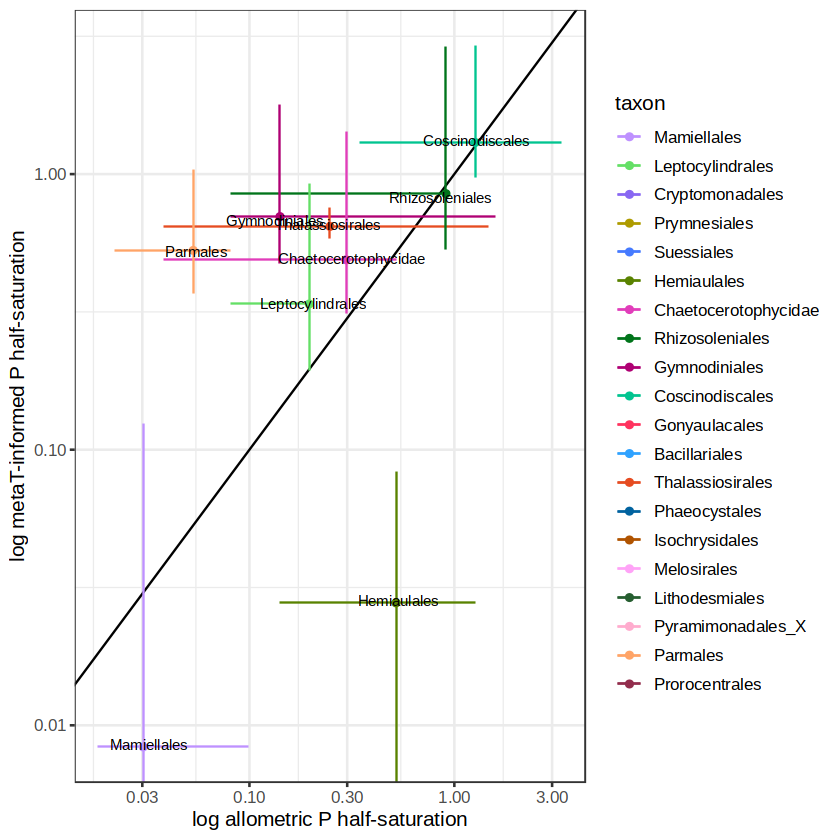

In [29]:
p_half_sat = ggplot(scaling_relationships %>%
                   dplyr::mutate(taxon=factor(taxon))%>%
                   dplyr::filter(metaT_p_half_sat>0)%>%
                   dplyr::mutate(conf_interval_intercept_low=case_when(conf_interval_intercept_low<0~0,
                                          TRUE~conf_interval_intercept_low)))+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_p,
                    y=metaT_p_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_segment(aes(x=half_sat_p_min,xend=half_sat_p_max,
                    y=metaT_p_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_segment(aes(x=half_sat_p,
                    y=conf_interval_intercept_low,
                    yend=conf_interval_intercept_high,
                    color=taxon),show.legend = TRUE)+
     geom_text(aes(x=half_sat_p,
                   y=metaT_p_half_sat,
                   label=taxon),
               position="jitter",size=3) + 
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE)+ 
    xlab("log allometric P half-saturation")+
    ylab("log metaT-informed P half-saturation") + scale_y_log10() + scale_x_log10()
p_half_sat

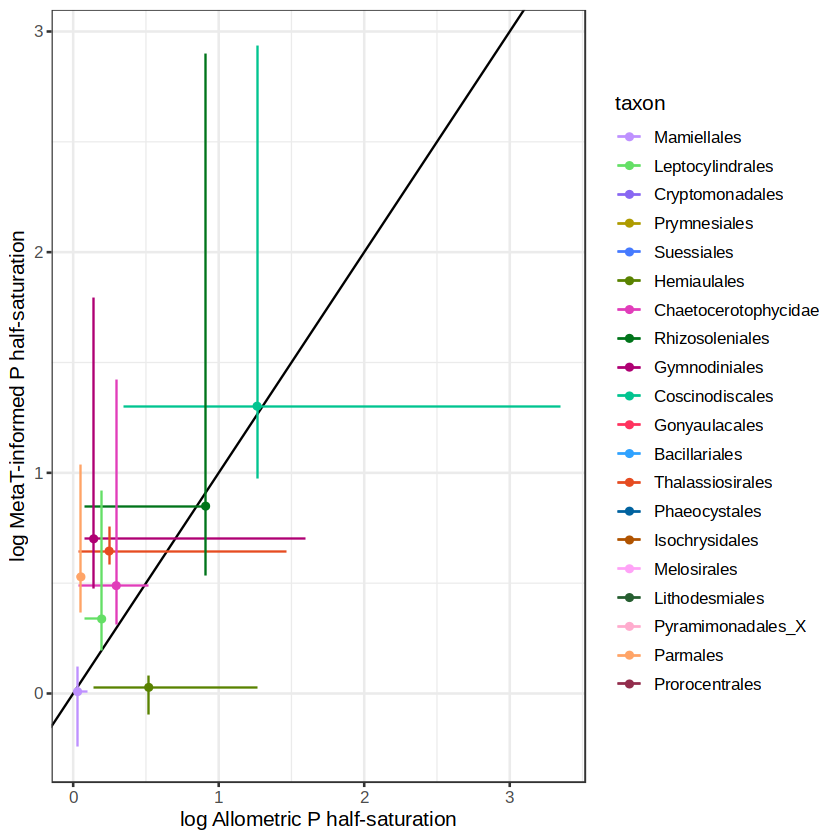

In [8]:
p_half_sat = ggplot(scaling_relationships %>%
                   dplyr::mutate(taxon=factor(taxon))%>%
                   dplyr::filter(metaT_p_half_sat>0))+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_p,
                    y=metaT_p_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_segment(aes(x=half_sat_p_min,xend=half_sat_p_max,
                    y=metaT_p_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_segment(aes(x=half_sat_p,
                    y=conf_interval_intercept_low,
                    yend=conf_interval_intercept_high,
                    color=taxon),show.legend = TRUE)+
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE)+ 
    xlab("log Allometric P half-saturation")+
    ylab("log MetaT-informed P half-saturation") #+ scale_y_log10() + scale_x_log10()
p_half_sat

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”


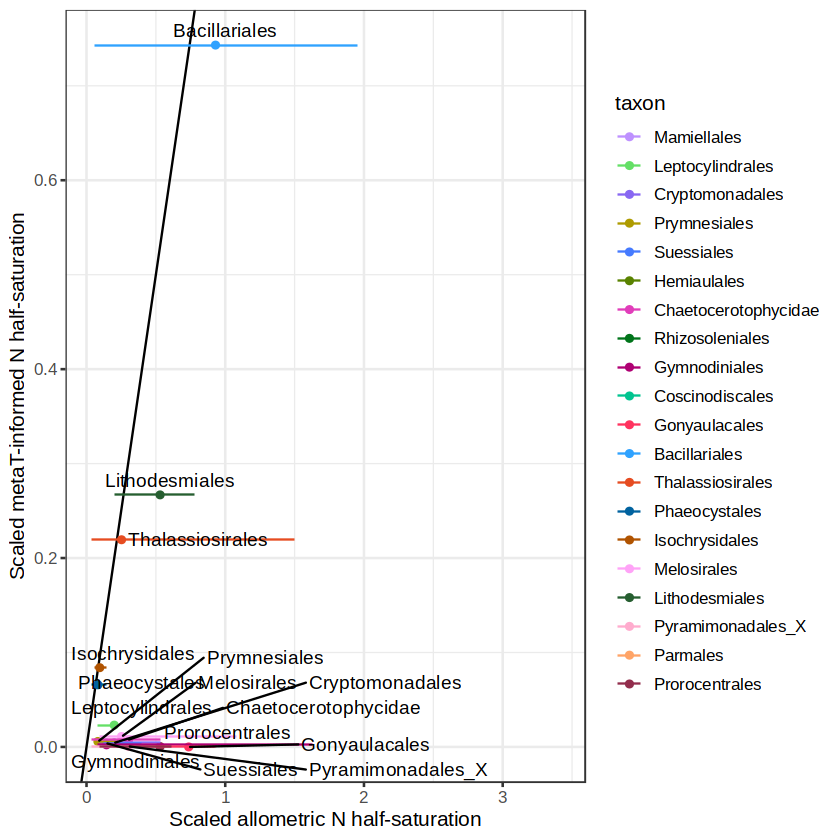

In [9]:
n_half_sat = ggplot(scaling_relationships)+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_n/16,
                    y=metaT_n_half_sat/16,
                    color=taxon),show.legend=TRUE)+
     geom_segment(aes(x=half_sat_n_min/16,xend=half_sat_n_max/16,
                    y=metaT_n_half_sat/16,
                    color=taxon),show.legend = TRUE)+
     geom_text_repel(aes(x=half_sat_n/16,
                   y=metaT_n_half_sat/16,
                   label=taxon),
               position="jitter",size=4,max.overlaps = Inf) + 
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE) + 
    xlab("Scaled allometric N half-saturation")+
    ylab("Scaled metaT-informed N half-saturation")
n_half_sat

In [52]:
scaling_relationships

X,Unnamed..0,taxon,diameter,min_diameter,max_diameter,pft,parameter_a_gr,parameter_a_gr_denom,parameter_b_gr,⋯,half_sat_n_max,half_sat_p_max,Taxon_x,metaT_p_half_sat,conf_interval_intercept_low,conf_interval_intercept_high,Taxon_y,metaT_n_half_sat,n_low,n_high
<int>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
0,0,Mamiellales,1.5,0.8,6.5,PicoEuk,1.284491e-05,86400,0.28,⋯,1.625468,0.09944038,Mamiellales,0.00834472,-0.2422768,0.12402586,,NA,NA,NA
1,1,Leptocylindrales,15.0,5.0,16.0,Diatom,2.889699e-05,86400,-0.10,⋯,3.371753,0.20627194,Leptocylindrales,0.33780248,0.1937571,0.92168624,Leptocylindrales,6.682673e-01,3.937778e-01,9.911955e-01
2,2,Cryptomonadales,15.0,6.0,50.0,PicoEuk,1.284491e-05,86400,0.28,⋯,8.485633,0.51912110,,NA,NA,NA,Cryptomonadales,2.138761e-01,1.771295e-03,8.404073e-01
3,4,Prymnesiales,5.0,4.0,18.0,PicoEuk,1.284491e-05,86400,0.28,⋯,3.709277,0.22692049,,NA,NA,NA,Prymnesiales,1.746112e-01,3.759355e-02,4.697318e-01
5,6,Hemiaulales,50.0,10.0,150.0,Diatom,2.889699e-05,86400,-0.10,⋯,20.661054,1.26397038,Hemiaulales,0.02780457,-0.0961801,0.08316536,,NA,NA,NA
6,7,Chaetocerotophycidae,25.0,2.0,50.0,Diatom,2.889699e-05,86400,-0.10,⋯,8.485633,0.51912110,Chaetocerotophycidae,0.48871507,0.3108869,1.42229430,Chaetocerotophycidae,6.691966e-02,1.417637e-05,2.494441e-01
7,8,Rhizosoleniales,100.0,5.0,100.0,Diatom,2.889699e-05,86400,-0.10,⋯,14.877109,0.91012905,Rhizosoleniales,0.84905727,0.5347575,2.89881445,,NA,NA,NA
8,9,Gymnodiniales,10.0,5.0,200.0,Dino,1.546644e-05,86400,-0.10,⋯,26.082719,1.59564866,Gymnodiniales,0.70103822,0.4755004,1.79404460,Gymnodiniales,8.188421e-02,5.662049e-03,2.315482e-01
9,10,Coscinodiscales,150.0,30.0,500.0,Diatom,2.889699e-05,86400,-0.10,⋯,54.787850,3.35172732,Coscinodiscales,1.30207709,0.9738541,2.93846217,,NA,NA,NA


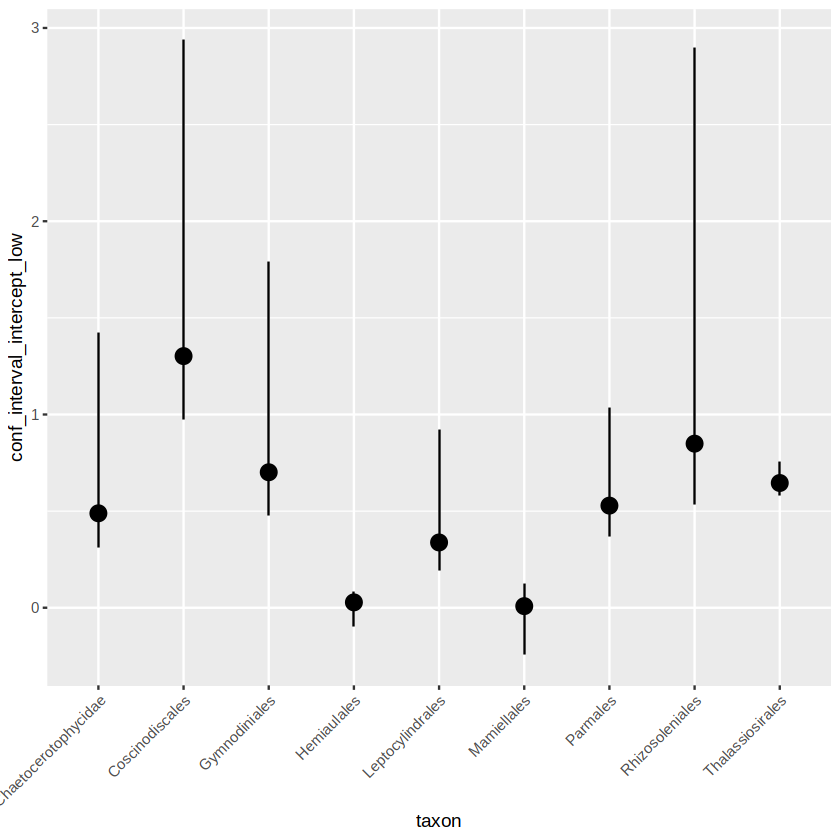

In [17]:
ggplot(scaling_relationships %>% 
       dplyr::filter(!is.na(metaT_p_half_sat))) + 
    geom_segment(aes(x=taxon,y=conf_interval_intercept_low,yend=conf_interval_intercept_high))+
    geom_point(aes(x=taxon,y=metaT_p_half_sat),size=4)+
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

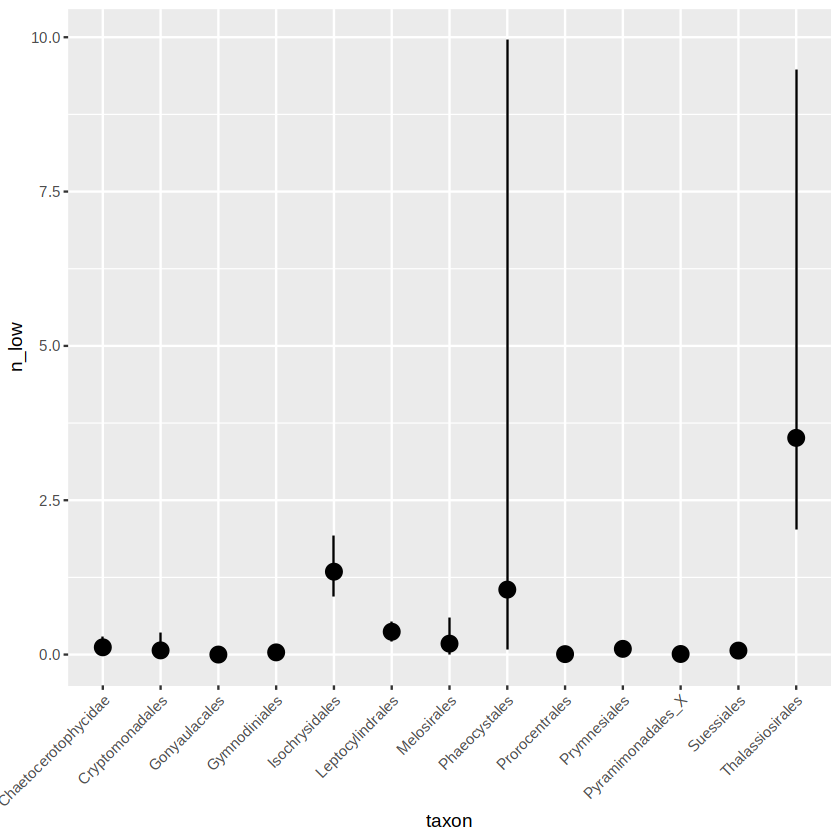

In [11]:
ggplot(scaling_relationships %>% 
       dplyr::filter(!is.na(metaT_n_half_sat)) %>%
       dplyr::filter(taxon!="Lithodesmiales")%>%
       dplyr::filter(taxon!="Bacillariales")) + 
    geom_segment(aes(x=taxon,y=n_low,yend=n_high))+
    geom_point(aes(x=taxon,y=metaT_n_half_sat),size=4)+
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [37]:
scaling_relationships %>% dplyr::select(half_sat_n_min,
                                        half_sat_n_max,half_sat_p_min,
                                        half_sat_p_max,n_low,n_high,
                                        conf_interval_intercept_low,
                                        conf_interval_intercept_high,taxon) %>%
    dplyr::mutate(dist_allometry_p=half_sat_p_max-half_sat_p_min,
                  dist_metaT_p=conf_interval_intercept_high-conf_interval_intercept_low,
                  dist_allometry_n=half_sat_n_max-half_sat_n_min,
                  dist_metaT_n=n_high-n_low)

half_sat_n_min,half_sat_n_max,half_sat_p_min,half_sat_p_max,n_low,n_high,conf_interval_intercept_low,conf_interval_intercept_high,taxon,dist_allometry_p,dist_metaT_p,dist_allometry_n,dist_metaT_n
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
0.2978664,1.625468,0.01822241,0.09944038,NA,NA,-0.2422768,0.12402586,Mamiellales,0.08121797,0.3663026,1.327601,NA
1.3142690,3.371753,0.08040234,0.20627194,2.108046e-01,5.307193e-01,0.1937571,0.92168624,Leptocylindrales,0.12586961,0.7279292,2.057484,3.199147e-01
1.5234250,8.485633,0.09319776,0.51912110,6.690292e-06,3.512116e-01,NA,NA,Cryptomonadales,0.42592333,NA,6.962208,3.512049e-01
1.0969508,3.709277,0.06710758,0.22692049,2.687396e-02,2.121527e-01,NA,NA,Prymnesiales,0.15981291,NA,2.612326,1.852788e-01
1.9231867,6.356436,0.11765377,0.38886432,1.859379e-02,1.363811e-01,NA,NA,Suessiales,0.27121054,NA,4.433249,1.177873e-01
2.3041914,20.661054,0.14096230,1.26397038,NA,NA,-0.0961801,0.08316536,Hemiaulales,1.12300808,0.1793455,18.356863,NA
0.6256808,8.485633,0.03827695,0.51912110,7.895841e-03,2.909687e-01,0.3108869,1.42229430,Chaetocerotophycidae,0.48084415,1.1114074,7.859952,2.830729e-01
1.3142690,14.877109,0.08040234,0.91012905,NA,NA,0.5347575,2.89881445,Rhizosoleniales,0.82972671,2.3640569,13.562840,NA
1.3142690,26.082719,0.08040234,1.59564866,1.298158e-02,6.973285e-02,0.4755004,1.79404460,Gymnodiniales,1.51524632,1.3185442,24.768450,5.675127e-02


Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”


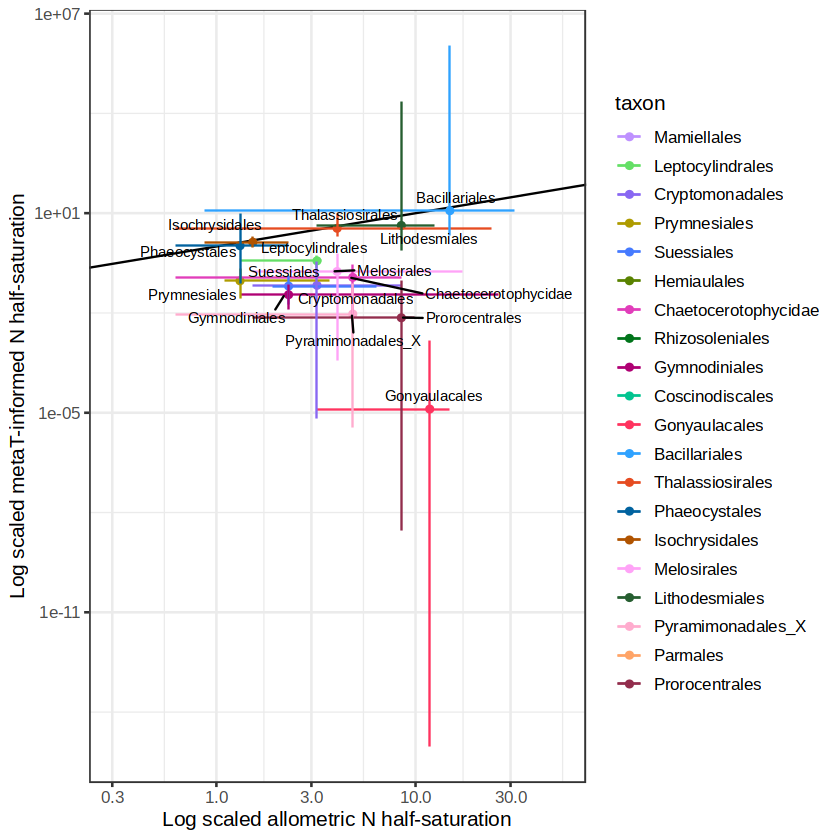

In [25]:
n_half_sat = ggplot(scaling_relationships %>%
                   dplyr::mutate(n_low=case_when(n_low<0~0,
                                                 TRUE~n_low)))+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_n,
                    y=metaT_n_half_sat,
                    color=taxon),show.legend=TRUE)+
     geom_segment(aes(x=half_sat_n_min,xend=half_sat_n_max,
                    y=metaT_n_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_segment(aes(x=half_sat_n,
                    y=n_low,
                    yend=n_high,
                    color=taxon),show.legend = TRUE)+
     geom_text_repel(aes(x=half_sat_n,
                   y=metaT_n_half_sat,
                   label=taxon),
               position="jitter",size=3,max.overlaps = Inf) + 
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE) + 
    xlab("Log scaled allometric N half-saturation")+
    ylab("Log scaled metaT-informed N half-saturation") + 
    scale_y_log10() + scale_x_log10()
n_half_sat

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”


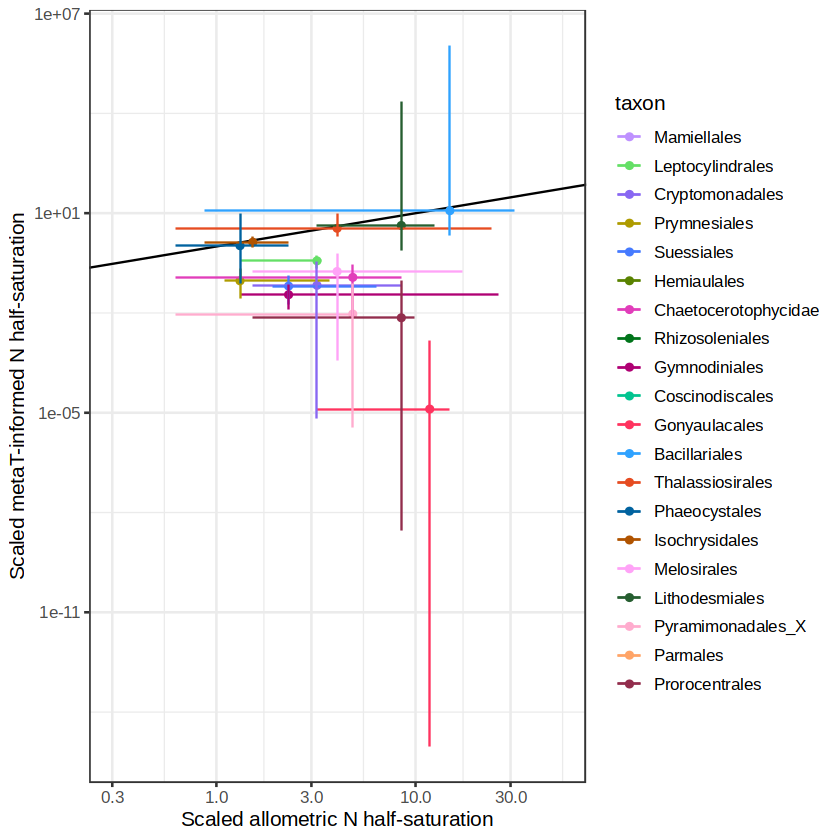

In [21]:
n_half_sat = ggplot(scaling_relationships %>%
                   dplyr::mutate(n_low=case_when(n_low<0~0,
                                                 TRUE~n_low)))+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_n,
                    y=metaT_n_half_sat,
                    color=taxon),show.legend=TRUE)+
     geom_segment(aes(x=half_sat_n_min,xend=half_sat_n_max,
                    y=metaT_n_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_segment(aes(x=half_sat_n,
                    y=n_low,
                    yend=n_high,
                    color=taxon),show.legend = TRUE)+
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE) + 
    xlab("Scaled allometric N half-saturation")+
    ylab("Scaled metaT-informed N half-saturation") + 
    scale_y_log10() + scale_x_log10()
n_half_sat

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_segment()`).”


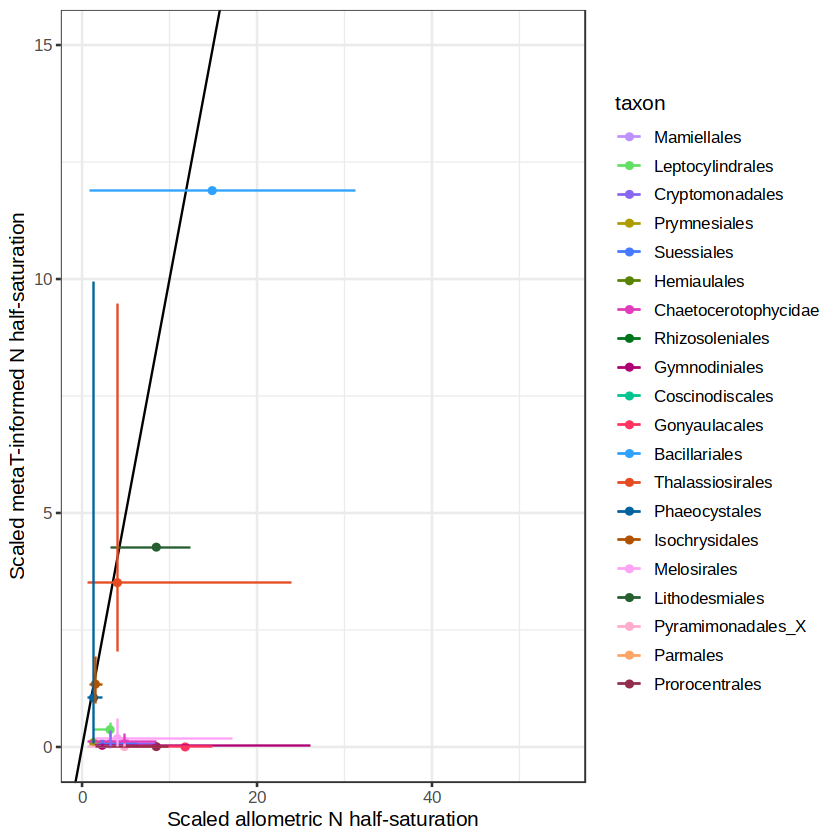

In [15]:
n_half_sat = ggplot(scaling_relationships)+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_n,
                    y=metaT_n_half_sat,
                    color=taxon),show.legend=TRUE)+
     geom_segment(aes(x=half_sat_n_min,xend=half_sat_n_max,
                    y=metaT_n_half_sat,
                    color=taxon),show.legend = TRUE)+
     geom_segment(aes(x=half_sat_n,
                    y=n_low,
                    yend=n_high,
                    color=taxon),show.legend = TRUE)+
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE) + 
    xlab("Scaled allometric N half-saturation")+
    ylab("Scaled metaT-informed N half-saturation") + ylim(c(0,15))
n_half_sat

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”


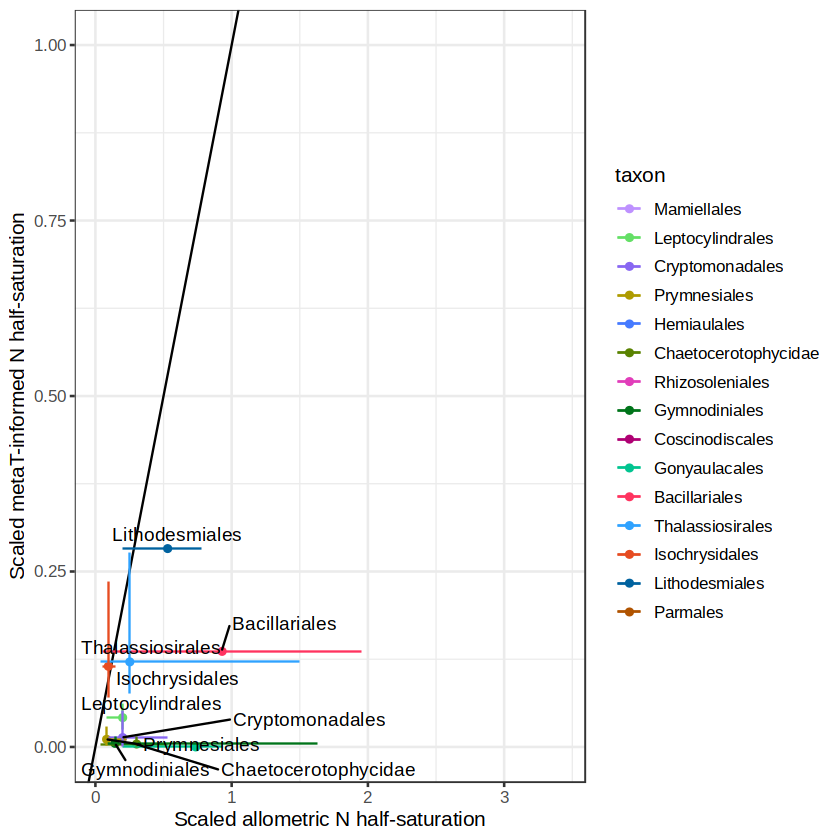

In [40]:
n_half_sat = ggplot(scaling_relationships)+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_n/16,
                    y=metaT_n_half_sat/16,
                    color=taxon),show.legend=TRUE)+
     geom_segment(aes(x=half_sat_n_min/16,xend=half_sat_n_max/16,
                    y=metaT_n_half_sat/16,
                    color=taxon),show.legend = TRUE)+
     geom_segment(aes(x=half_sat_n/16,
                    y=n_low/16,
                    yend=n_high/16,
                    color=taxon),show.legend = TRUE)+
     geom_text_repel(aes(x=half_sat_n/16,
                   y=metaT_n_half_sat/16,
                   label=taxon),
               position="jitter",size=4,max.overlaps = Inf) + 
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE) + 
    xlab("Scaled allometric N half-saturation")+
    ylab("Scaled metaT-informed N half-saturation") + ylim(c(0,1))
n_half_sat

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”


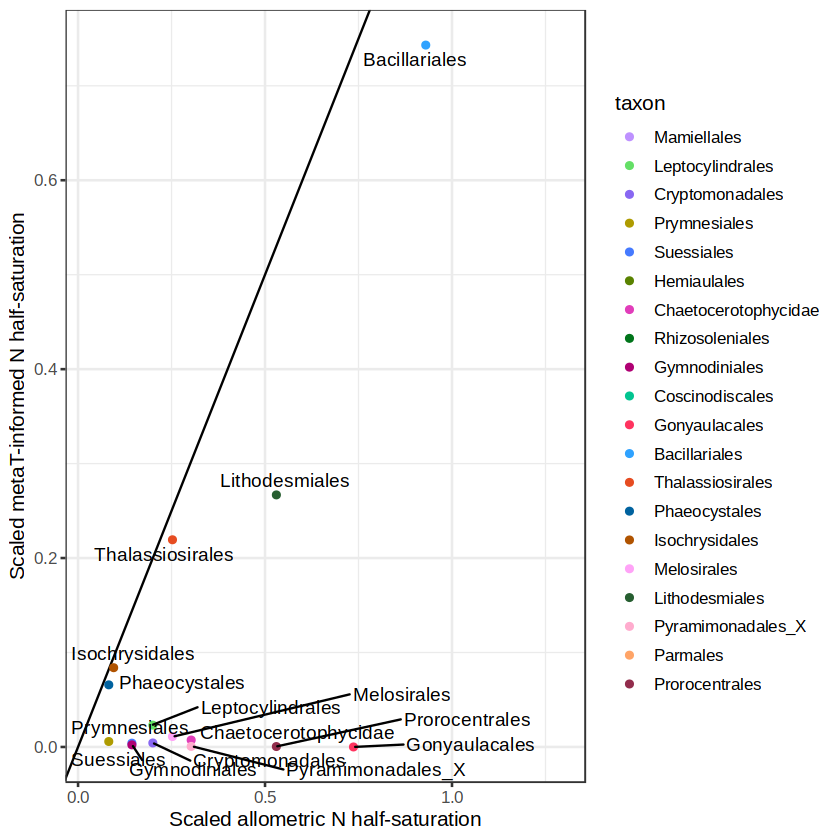

In [12]:
n_half_sat = ggplot(scaling_relationships)+
     geom_abline(aes(intercept=0,
                     slope=1))+
     geom_point(aes(x=half_sat_n/16,
                    y=metaT_n_half_sat/16,
                    color=taxon),show.legend=TRUE)+
     geom_text_repel(aes(x=half_sat_n/16,
                   y=metaT_n_half_sat/16,
                   label=taxon),
               position="jitter",size=4,max.overlaps = Inf) + 
     theme_bw(base_size=12) +
     scale_color_manual(values=c("#be91ff",
"#64df66",
"#8867f2",
"#ae9b00",
"#457aff",
"#598200",
"#e13dba",
"#00741a",
"#af0073",
"#01c490",
"#ff335f",
"#2fa2ff",
"#e64c21",
"#00629f",
"#b05300",
"#ffa3f7",
"#265e30",
"#ffacce",
"#ffa467",
"#922d4c",
"#e5c18b",
"#9f6283","red"),breaks=unique(scaling_relationships$taxon),drop = FALSE) + 
    xlab("Scaled allometric N half-saturation")+
    ylab("Scaled metaT-informed N half-saturation")
n_half_sat

In [6]:
summary(lm(half_sat_p~metaT_p_half_sat,data=scaling_relationships %>% 
            dplyr::filter(taxon!="Coscinodiscales")))


Call:
lm(formula = half_sat_p ~ metaT_p_half_sat, data = scaling_relationships %>% 
    dplyr::filter(taxon != "Coscinodiscales"))

Residuals:
     Min       1Q   Median       3Q      Max 
-0.27190 -0.15462 -0.09167  0.07703  0.48115 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)
(Intercept)        0.1538     0.1943   0.791    0.459
metaT_p_half_sat   0.3241     0.3655   0.887    0.409

Residual standard error: 0.2956 on 6 degrees of freedom
  (11 observations deleted due to missingness)
Multiple R-squared:  0.1159,	Adjusted R-squared:  -0.03146 
F-statistic: 0.7865 on 1 and 6 DF,  p-value: 0.4093


In [7]:
summary(lm(metaT_n_half_sat~half_sat_n,data=scaling_relationships))


Call:
lm(formula = metaT_n_half_sat ~ half_sat_n, data = scaling_relationships)

Residuals:
    Min      1Q  Median      3Q     Max 
-4.9182 -1.0502 -0.0802  1.2305  5.4050 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)   
(Intercept)  -1.0517     1.0573  -0.995  0.33801   
half_sat_n    0.5066     0.1644   3.082  0.00875 **
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.492 on 13 degrees of freedom
  (5 observations deleted due to missingness)
Multiple R-squared:  0.4222,	Adjusted R-squared:  0.3777 
F-statistic: 9.498 on 1 and 13 DF,  p-value: 0.008746


In [8]:
scaling_relationships %>% dplyr::mutate(n_distance=abs(metaT_n_half_sat-half_sat_n)/
                                        (metaT_n_half_sat+half_sat_n)/2,
                                        p_distance=abs(metaT_p_half_sat-half_sat_p)/
                                        (metaT_p_half_sat+half_sat_p)/2) %>%
    dplyr::summarize(avg_p_dist=mean(p_distance,na.rm=T),
                     sd_p_dist=sd(p_distance,na.rm=T),
                     avg_n_dist=mean(n_distance,na.rm=T),
                     sd_n_dist=mean(n_distance,na.rm=T))

avg_p_dist,sd_p_dist,avg_n_dist,sd_n_dist
<dbl>,<dbl>,<dbl>,<dbl>
0.2198057,0.1613062,0.3361623,0.3361623


Warning message:
“Removed 16 rows containing missing values or values outside the scale range
(`geom_point()`).”
Saving 7 x 7 in image
Warning message:
“Removed 16 rows containing missing values or values outside the scale range
(`geom_point()`).”


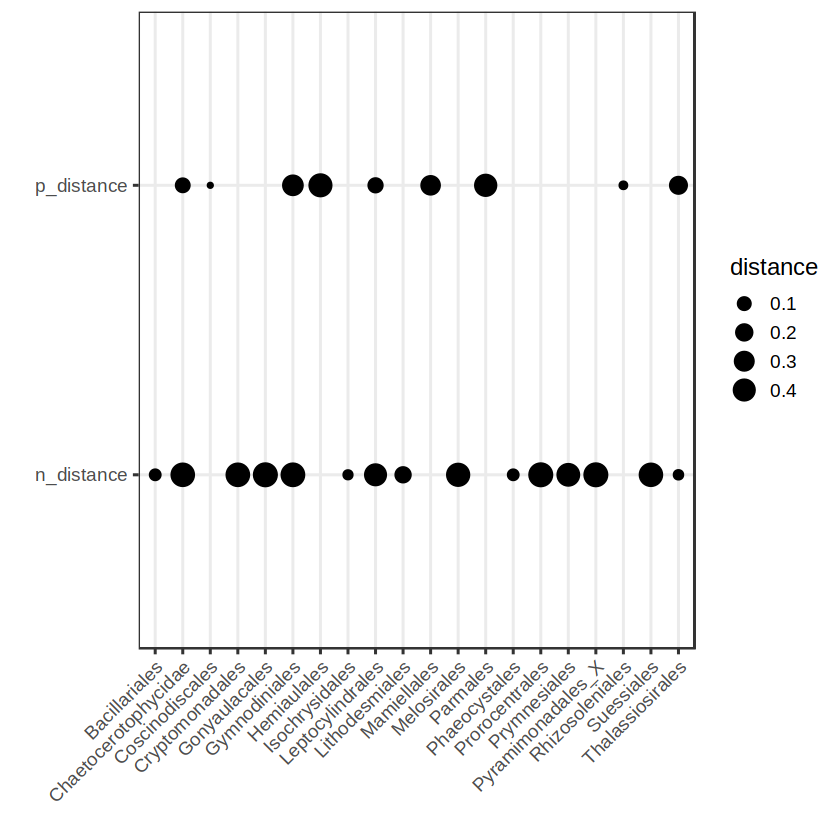

In [30]:
ggplot(scaling_relationships %>% dplyr::mutate(n_distance=abs(metaT_n_half_sat-half_sat_n)/
                                        (metaT_n_half_sat+half_sat_n)/2,
                                        p_distance=abs(metaT_p_half_sat-half_sat_p)/
                                        (metaT_p_half_sat+half_sat_p)/2) %>%
      tidyr::pivot_longer(cols = c("n_distance","p_distance"),names_to = "variable",
                          values_to="distance")) + theme_bw(base_size=14)+
    geom_point(aes(x=taxon,size=distance,y=variable))+
    theme(axis.text.x = element_text(angle = 45, hjust = 1))  +ylab("")+xlab("")

ggsave("../figures/supp_distances.pdf")

In [31]:
p_merge = (n_half_sat | p_half_sat) + plot_layout(guides = "collect") & plot_annotation(tag_levels = "A")
ggsave("../figures/half_sats_2.png",plot=p_merge,width=10,height=6,units="in")

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”


In [32]:
ggsave("../figures/half_sats_2.pdf",plot=p_merge,width=12,height=6,units="in")

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”
Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”


Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”


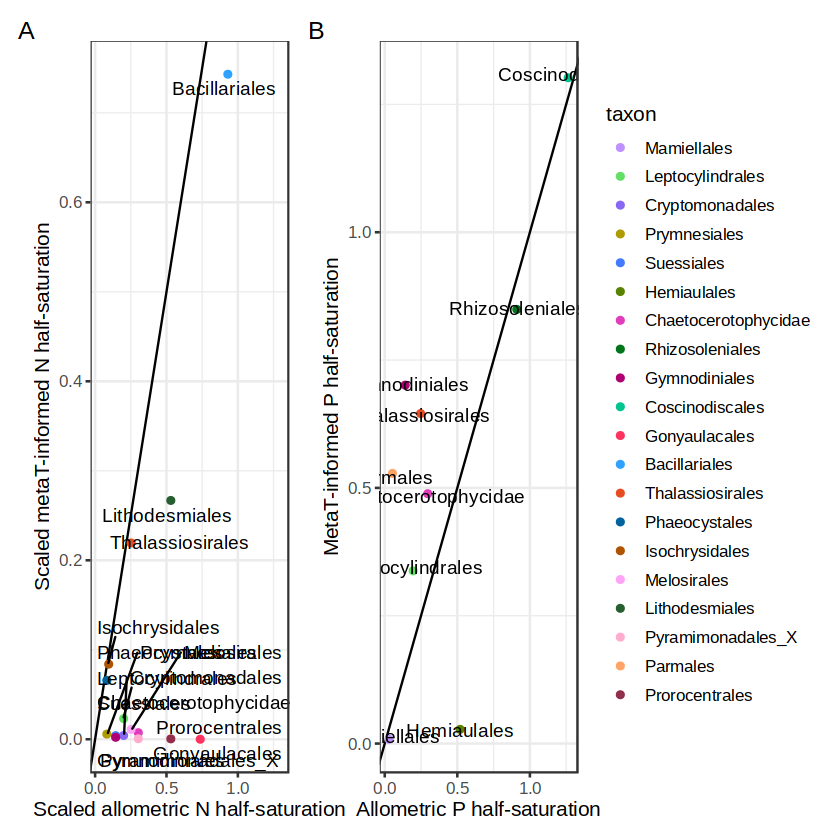

In [23]:
p_merge
ggsave("../figures/fig3.pdf",width=12,height=6,units="in")

In [15]:
p_merge = (n_half_sat | p_half_sat) + plot_layout(guides = "collect") & plot_annotation(tag_levels = "A")
ggsave("../figures/half_sats_range.png",plot=p_merge,width=10,height=6,units="in")

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”
